In [1]:
import mikeio
import modelskill as ms
import matplotlib.pyplot as plt 
import pandas as pd

In [2]:
ms.options.metrics.list = ["urmse", "mae", "cc", "si", "r2"]

In [3]:
# mr_fldr = "../output_sample/"
mr_fldr = '../output/' # Change the output folder if needed  

fig_fldr = "../figures/"
save_png = False if "sample" in mr_fldr else True

mr_fn = "3D_2023_2025_hrly.dfsu" # model result file name

obs_fldr = "../observations/" 

In [4]:

time_start = pd.Timestamp("2023-01-01 00:00:00")
time_end = pd.Timestamp("2025-12-31 23:00:00")

In [5]:
# ds = mikeio.read(f"{mr_fldr}{mr_fn}",items=[4,5],time = slice(time_start, time_end))
# ds.items

In [6]:
stations = pd.read_csv("../observations/stations_TS.csv",sep=";")
stations

,Station,lon,lat,utm33,Unnamed: 4
0,FRB9070,12.638,55.924,352413.807,6200141.382
1,KBH431,12.750,55.867,359204.271,6193565.983
2,KBK1728,12.714,55.537,355741.165,6156924.163


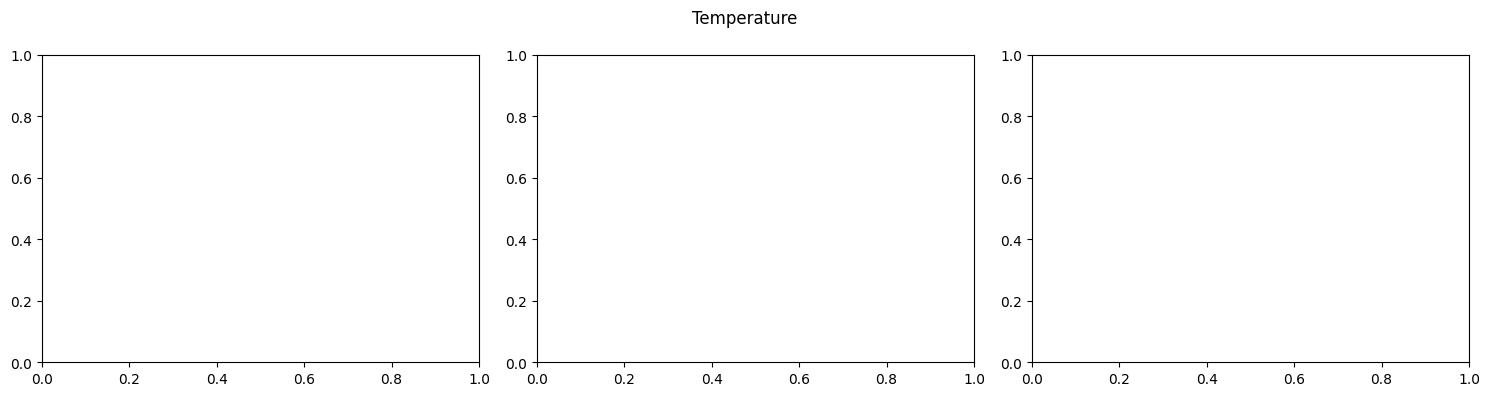

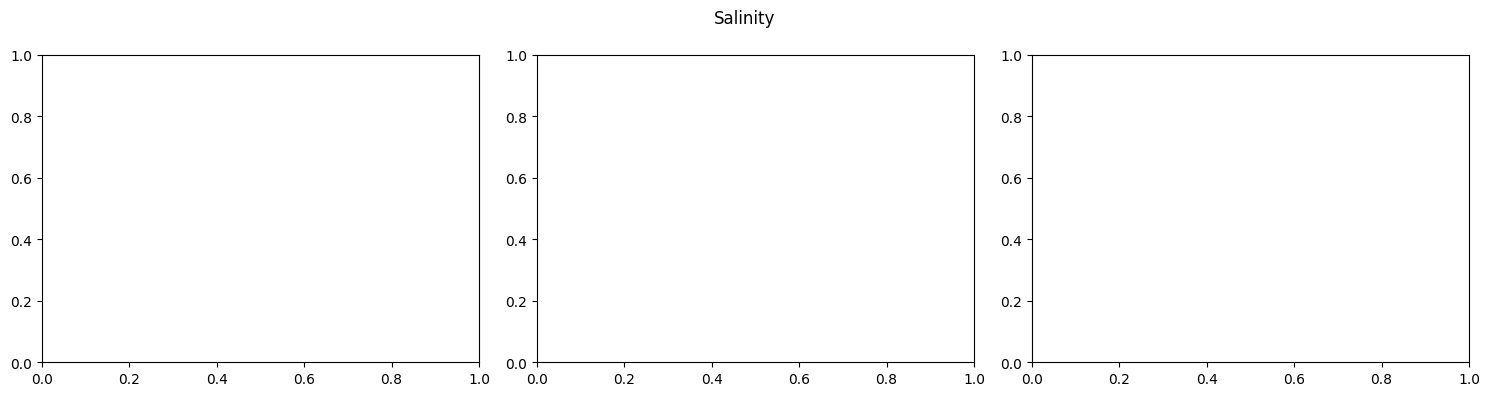

In [7]:
station_names = stations["Station"].unique()

# Pick 5 colors, one for each depth
colors = ["blue", "orange", "green", "red", "purple"]

variables = ["T", "S"]
var_items = [4, 5]  # Model item indices for T and S
titles = {"T": "Temperature", "S": "Salinity"}

for var_idx, var in enumerate(variables):
    fig, axs = plt.subplots(nrows=1, ncols=len(station_names), figsize=(15, 4))
    
    for i, station_name in enumerate(station_names):
        # Read the observation data
        if var == "T":
            obs_data = pd.read_csv(f"{obs_fldr}{station_name}_T_All.csv", index_col=0, parse_dates=True).loc[time_start:time_end]
        else:
            obs_data = pd.read_csv(f"{obs_fldr}{station_name}_S_All.csv", index_col=0, parse_dates=True).loc[time_start:time_end]
        
        st_info = stations[stations["Station"] == station_name]
        
        # Identify depth columns (those ending with 'm')
        depth_cols = [col for col in obs_data.columns if col.endswith('m')]
        
        # Get all unique observation times for this station, rounded to nearest hour
        all_obs_times = obs_data.dropna().index.tolist()
        if not all_obs_times:
            continue
            
        obs_times_rounded = pd.DatetimeIndex(all_obs_times).round('H').unique().tolist()
        
        # Load model data once per station for all observation times
        try:
            ds_model = mikeio.read(f"{mr_fldr}{mr_fn}", items=[var_items[var_idx]], 
                                  time=slice(obs_times_rounded[0], obs_times_rounded[-1]))
        except Exception as e:
            print(f"Error loading model data for {station_name}: {e}")
            continue
        
        for j, depth_col in enumerate(depth_cols):
            # Extract depth value from column name (e.g., "0m" -> 0)
            try:
                depth_val = float(depth_col.rstrip('m'))
            except ValueError:
                continue
            
            obs_var = obs_data[depth_col]
            # Remove NaN values to get valid observation dates
            obs_var_valid = obs_var.dropna()
            
            if obs_var_valid.empty:
                continue
            
            # Plot observation data with full dots
            axs[i].scatter(obs_var_valid.index, obs_var_valid.values, label=f"{var} (obs) d={depth_val:.0f}m", 
                          color=colors[j % len(colors)], marker="o", s=40, alpha=0.7)
            
            # Get model data at this depth
            try:
                model_var = ds_model[0].sel(x=st_info['Longitude'].values[0], 
                                            y=st_info['Latitude'].values[0], 
                                            z=-depth_val)
                
                # Select only times matching observation dates
                obs_times_this_depth = obs_var_valid.index.round('H').unique()
                model_var_subset = model_var.sel(time=obs_times_this_depth, method='nearest')
                
                axs[i].plot(model_var_subset.time, model_var_subset.values, 
                           label=f"{var} (model) d={-model_var.geometry.z:.2f}m", 
                           color=colors[j % len(colors)], linewidth=2, marker="*", markersize=10)
            except (ValueError, IndexError) as e:
                # Try with closest depth if exact depth not found
                try:
                    all_depths = ds_model[0].sel(x=st_info['Longitude'].values[0],
                                                 y=st_info['Latitude'].values[0]).geometry.element_coordinates[:, -1]
                    closest_depth = all_depths.min()
                    
                    if abs(closest_depth - depth_val) < 1:  # Within 1m tolerance
                        model_var = ds_model[0].sel(x=st_info['Longitude'].values[0],
                                                    y=st_info['Latitude'].values[0],
                                                    z=closest_depth.item())
                        
                        obs_times_this_depth = obs_var_valid.index.round('H').unique()
                        model_var_subset = model_var.sel(time=obs_times_this_depth, method='nearest')
                        
                        axs[i].plot(model_var_subset.time, model_var_subset.values, 
                                   label=f"{var} (model) d={-model_var.geometry.z:.2f}m", 
                                   color=colors[j % len(colors)], linewidth=2, marker="*", markersize=10)
                except (ValueError, IndexError) as e:
                    print(f"Could not plot model data for {station_name} at depth {depth_val}m: {e}")
        
        axs[i].set_title(station_name)
        axs[i].set_xlabel("Time")
        axs[i].set_ylabel(f"{var}")
        if i == 0:
            axs[i].legend(loc='upper left', fontsize=8, bbox_to_anchor=(-0.15, 1))
        axs[i].grid(alpha=0.3)
    
    plt.suptitle(titles[var])
    plt.tight_layout()
    if save_png:
        plt.savefig(f"{fig_fldr}model_validation_3D_{var.lower()}.png", dpi=150, bbox_inches='tight')
    plt.show()

In [8]:
# Debug: Check model data loading for first station and variable
station_name = stations["Station"].unique()[0]
var_idx = 0
var = "T"

obs_data = pd.read_csv(f"{obs_fldr}{station_name}_T_All.csv", index_col=0, parse_dates=True).loc[time_start:time_end]
st_info = stations[stations["Station"] == station_name]

print(f"Station: {station_name}")
print(f"Longitude: {st_info['Longitude'].values[0]}, Latitude: {st_info['Latitude'].values[0]}")

# Get observation times
all_obs_times = obs_data.dropna().index.tolist()
print(f"Number of observation times: {len(all_obs_times)}")
print(f"First obs time: {all_obs_times[0]}, Last obs time: {all_obs_times[-1]}")

obs_times_rounded = pd.DatetimeIndex(all_obs_times).round('H').unique().tolist()
print(f"Number of rounded unique times: {len(obs_times_rounded)}")

# Try loading model data
ds_model = mikeio.read(f"{mr_fldr}{mr_fn}", items=[4], 
                      time=slice(obs_times_rounded[0], obs_times_rounded[-1]))

print(f"\nModel data shape: {ds_model[0].shape}")
print(f"Model times: {len(ds_model[0].time)} timesteps")
print(f"Available depths: {ds_model[0].geometry.element_coordinates[:, -1]}")

# Try selecting at station location
model_var = ds_model[0].sel(x=st_info['Longitude'].values[0], 
                            y=st_info['Latitude'].values[0], 
                            z=-0)

print(f"Selected model var shape: {model_var.shape}")
print(f"Selected model var sample values: {model_var.values[:5]}")

Station: FRB9070


KeyError: 'Longitude'